<a href="https://colab.research.google.com/github/Aisyaaswy/Pemrograman_Mesin/blob/main/jobsheet_4/dataset_pbl/praktikum_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRAKTIKUM 1**
# **KMeans**

In [1]:
# Persiapan data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')
df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [2]:
# Seleksi Fitur numerik yang relevan untuk klasterisasi
fitur = ['Age', 'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 'Stress Level', 'Heart Rate', 'Daily Steps']
X_raw = df[fitur]
y = df['Sleep Disorder'].fillna('None')

# Standarisasi fitur agar skala angka seragam (wajib untuk K-Means)
scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(X_raw), columns=fitur)
X.head()

,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps
0,-1.753096,-1.298887,-1.098280,-0.825418,0.347021,1.654719,-1.619584
1,-1.637643,-1.173036,-1.098280,0.039844,1.475592,1.170474,1.970077
2,-1.637643,-1.173036,-1.098280,0.039844,1.475592,1.170474,1.970077
3,-1.637643,-1.550588,-2.771424,-1.402260,1.475592,3.591698,-2.362273
4,-1.637643,-1.550588,-2.771424,-1.402260,1.475592,3.591698,-2.362273


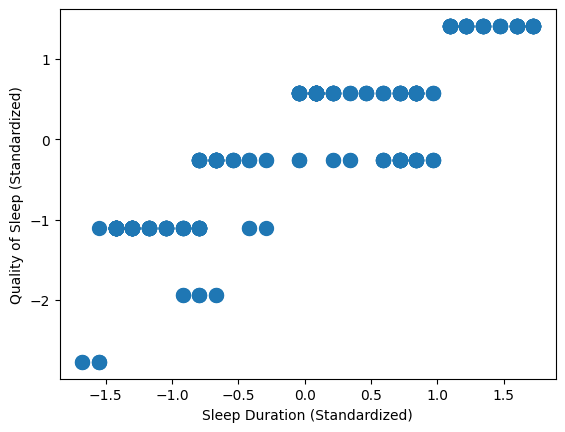

In [3]:
# Plot Data
# Plot data berdasarkan Sleep Duration (indeks 1) dan Quality of Sleep (indeks 2)
plt.scatter(X.iloc[:, 1], X.iloc[:, 2], s=100)
plt.xlabel('Sleep Duration (Standardized)')
plt.ylabel('Quality of Sleep (Standardized)')
plt.show()

In [4]:
# Buat Model KMeans
# Kita coba menggunakan k=3 (sesuai 3 kategori Sleep Disorder: None, Sleep Apnea, Insomnia)
cl_kmeans = KMeans(n_clusters=3, random_state=42)

# Fit dan predict model
y_kmeans = cl_kmeans.fit_predict(X)

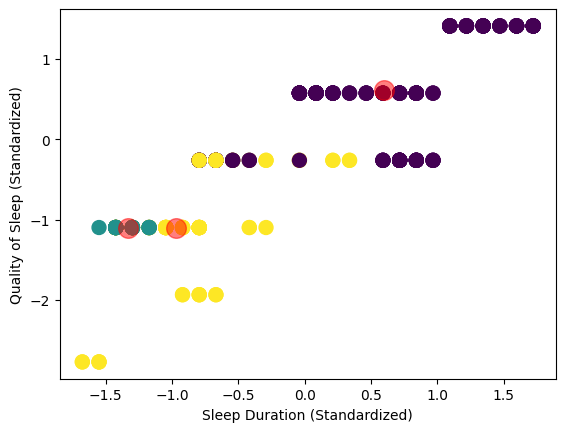

In [5]:
# Plot hasil cluster berdasarkan Sleep Duration dan Quality of Sleep
plt.scatter(X.iloc[:, 1], X.iloc[:, 2], s=100, c=y_kmeans)

# Plot centroid
centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 1], centers[:, 2], c='red', s=200, alpha=0.5)
plt.xlabel('Sleep Duration (Standardized)')
plt.ylabel('Quality of Sleep (Standardized)')
plt.show()

In [6]:
# Cek Nilai SSE
print(f'Nilai SSE: {cl_kmeans.inertia_}')

Nilai SSE: 1260.299049398345


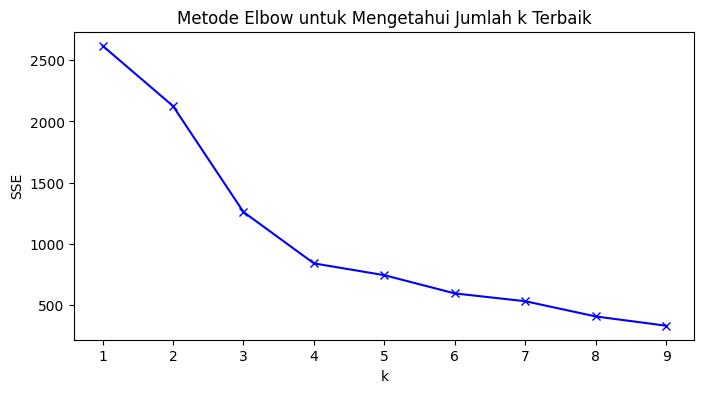

In [7]:
# Implementasi Metode Elbow
sse = []
K = range(1, 10)

for k in K:
    kmeanModel = KMeans(n_clusters=k, random_state=42)
    kmeanModel.fit(X)
    sse.append(kmeanModel.inertia_)

# Plotting the distortions
plt.figure(figsize=(8, 4))
plt.plot(K, sse, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Metode Elbow untuk Mengetahui Jumlah k Terbaik")
plt.show()

In [8]:
# Cek Nilai SSE setiap k
for idx, sse_val in enumerate(sse, start=1):
    print(f'k={idx}; SSE={sse_val}')

k=1; SSE=2617.9999999999995
k=2; SSE=2125.177928832989
k=3; SSE=1260.299049398345
k=4; SSE=840.5885205283749
k=5; SSE=744.1602884007998
k=6; SSE=595.2905927238147
k=7; SSE=531.6050549103876
k=8; SSE=407.30124587292556
k=9; SSE=331.5795794880619
